Me quedo con los de a combustion

In [445]:

import pandas as pd
import numpy as np

df = pd.read_excel('25-testcar-2026-01-21.xlsx')

In [446]:
df

,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,...,Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.000,RASXV04.0AES,Car,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.000,RASXV04.0AES,Car,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.000,PASXJ04.0AEX,Both,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.000,PASXJ04.0AEX,Both,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.200,SASXV05.2AMV,Car,...,-0.57,-0.0029,0.0128,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4282,2025,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Performance,GIC_C10_6119,0,0.001,SWHNV00.0LEB,Car,...,-8.08,-0.0412,0.0213,NaN,NaN,N,NaN,NaN,N,No averaging
4283,2025,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Performance,GIC_C10_6119,0,0.001,SWHNV00.0LEB,Car,...,-8.08,-0.0412,0.0213,NaN,NaN,N,NaN,NaN,N,No averaging
4284,2025,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Performance,GIC_C10_6119,0,0.001,SWHNV00.0LEB,Car,...,-7.96,0.0127,0.0206,NaN,NaN,N,NaN,NaN,N,No averaging
4285,2025,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Performance,GIC_C10_6119,0,0.001,SWHNV00.0LEB,Car,...,-8.08,-0.0412,0.0213,NaN,NaN,N,NaN,NaN,N,No averaging


In [447]:
col_fuel = "Test Fuel Type Description"

print(df[col_fuel].isna().sum(), "filas sin tipo de combustible")

# 1. Filtrar combustión interna (excluye eléctricos e hidrógeno)
sinCombustion = df[col_fuel].str.contains("Electricity|Hydrogen")
df_procesado = df[~sinCombustion] #invierte la condicion, deja los que son de combustion

0 filas sin tipo de combustible


In [448]:
df_procesado.info()

<class 'pandas.DataFrame'>
Index: 3623 entries, 0 to 4262
Data columns (total 67 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model Year                      3623 non-null   int64  
 1   Vehicle Manufacturer Name       3623 non-null   str    
 2   Veh Mfr Code                    3623 non-null   str    
 3   Represented Test Veh Make       3623 non-null   str    
 4   Represented Test Veh Model      3623 non-null   str    
 5   Test Vehicle ID                 3623 non-null   str    
 6   Test Veh Configuration #        3623 non-null   int64  
 7   Test Veh Displacement (L)       3623 non-null   float64
 8   Actual Tested Testgroup         3623 non-null   str    
 9   Vehicle Type                    3623 non-null   str    
 10  Rated Horsepower                3623 non-null   int64  
 11  # of Cylinders and Rotors       3617 non-null   float64
 12  Engine Code                     3623 non-null   st

solo con los de test urbanos

In [449]:
df_procesado = df_procesado[df_procesado["Test Category"] == "FTP"]

print(pd.crosstab(df_procesado["Test Procedure Description"], df_procesado["Test Category"]))

Test Category                               FTP
Test Procedure Description                     
CVS 75 and later (w/o can. load)             51
California fuel 2-day exhaust (w/can load)   11
Cold CO                                     221
Federal fuel 2-day exhaust (w/can load)     923
Federal fuel 3-day exhaust                  341


In [450]:
df_procesado.info()

<class 'pandas.DataFrame'>
Index: 1547 entries, 0 to 4261
Data columns (total 67 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model Year                      1547 non-null   int64  
 1   Vehicle Manufacturer Name       1547 non-null   str    
 2   Veh Mfr Code                    1547 non-null   str    
 3   Represented Test Veh Make       1547 non-null   str    
 4   Represented Test Veh Model      1547 non-null   str    
 5   Test Vehicle ID                 1547 non-null   str    
 6   Test Veh Configuration #        1547 non-null   int64  
 7   Test Veh Displacement (L)       1547 non-null   float64
 8   Actual Tested Testgroup         1547 non-null   str    
 9   Vehicle Type                    1547 non-null   str    
 10  Rated Horsepower                1547 non-null   int64  
 11  # of Cylinders and Rotors       1544 non-null   float64
 12  Engine Code                     1547 non-null   st

Dejo las muestras con las mismas configuraciones

In [451]:
CLAVE = ["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #"]
VARIABLES = [
    "Equivalent Test Weight (lbs.)",
    "Rated Horsepower",
    "Test Veh Displacement (L)",
    "# of Cylinders and Rotors",
    "Tested Transmission Type", 
    "Drive System Description"
]

variacion = df_procesado.groupby(CLAVE)[VARIABLES].nunique()

configuraciones_con_diferencias = variacion[
    (variacion > 1).any(axis=1)
]

print("Configuraciones con diferencias en características técnicas:",
      len(configuraciones_con_diferencias))

display(configuraciones_con_diferencias)

Configuraciones con diferencias en características técnicas: 0


,,,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors,Tested Transmission Type,Drive System Description
Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,,,,,,


In [452]:
df_procesado = (
    df_procesado
    .groupby(CLAVE, as_index=False)
    .agg({
        "RND_ADJ_FE": "mean",
        "Equivalent Test Weight (lbs.)": "first",
        "Rated Horsepower": "first",
        "Test Veh Displacement (L)": "first",
        "# of Cylinders and Rotors": "first",
        "Tested Transmission Type": "first",
        "Drive System Description": "first"
    })
)

df_procesado.count()

Veh Mfr Code                     1087
Test Vehicle ID                  1087
Test Veh Configuration #         1087
RND_ADJ_FE                       1087
Equivalent Test Weight (lbs.)    1087
Rated Horsepower                 1087
Test Veh Displacement (L)        1087
# of Cylinders and Rotors        1084
Tested Transmission Type         1087
Drive System Description         1087
dtype: int64

Empiezo a limpiar MPG

In [453]:
df_procesado["RND_ADJ_FE"].describe()

count     1087.000000
mean        58.403735
std        527.877806
min          9.500000
25%         22.300000
50%         27.200000
75%         33.750000
max      10000.000000
Name: RND_ADJ_FE, dtype: float64

Raro el maximo

In [454]:
mpg = "RND_ADJ_FE"

malos = df_procesado[df_procesado[mpg] >= 1000]
print(len(malos), "filas con MPG >= 1000")
print(malos[["Veh Mfr Code", "Test Vehicle ID","Test Veh Configuration #", mpg]])

4 filas con MPG >= 1000
    Veh Mfr Code    Test Vehicle ID  Test Veh Configuration #  RND_ADJ_FE
636          LTX       EDV-25-EVSA6                         0   10000.000
637          LTX       EDV-25-EVSM6                         0   10000.000
786          PGN  ZA9U11EBYYSF76004                         0   10000.000
891          TYX            20-UC1A                         0    2308.875


Se consideran numeros inposibles por lo que se convierten en Nan y se eliminan

In [455]:
mpg = "RND_ADJ_FE"

df_procesado.loc[df_procesado[mpg] >= 1000, mpg] = np.nan

print(df_procesado[mpg].isna().sum(), "MPG convertidos a faltante")  # debería dar 6
print(df_procesado[mpg].describe())

4 MPG convertidos a faltante
count    1083.000000
mean       28.786690
std         9.551012
min         9.500000
25%        22.300000
50%        27.200000
75%        33.700000
max        69.900000
Name: RND_ADJ_FE, dtype: float64


Maximos altos, supongo por hibridos

#### variables de caracteristicas

In [456]:
print("nulos:",df_procesado["Equivalent Test Weight (lbs.)"].isna().sum())
print(df_procesado["Equivalent Test Weight (lbs.)"].describe())
print(df_procesado["Equivalent Test Weight (lbs.)"].value_counts().head(5), "\n")

nulos: 0
count    1087.000000
mean     4557.152714
std       853.084541
min      2750.000000
25%      3875.000000
50%      4500.000000
75%      5000.000000
max      7000.000000
Name: Equivalent Test Weight (lbs.), dtype: float64
Equivalent Test Weight (lbs.)
4250    130
4750    121
4000    108
4500     98
5500     90
Name: count, dtype: int64 



parece todo bien

##### potencia

In [457]:

print("nulos:",df_procesado["Rated Horsepower"].isna().sum())
print(df_procesado["Rated Horsepower"].describe())
print(df_procesado["Rated Horsepower"].value_counts().head(5), "\n")

nulos: 0
count    1087.000000
mean      312.644894
std       144.726779
min         1.000000
25%       192.000000
50%       281.000000
75%       382.000000
max      1500.000000
Name: Rated Horsepower, dtype: float64
Rated Horsepower
375    45
255    40
400    33
201    22
300    22
Name: count, dtype: int64 



raro el minimos de potencia, 1 es imposible casi

In [458]:
hp = "Rated Horsepower"
df_procesado[df_procesado[hp] == 1]

,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,RND_ADJ_FE,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors,Tested Transmission Type,Drive System Description
299,FMX,SRE00010,0,32.8,3750,1,1.5,3.0,Automatic,Part-time 4-Wheel Drive
300,FMX,SRE00024,0,30.8,4000,1,1.5,3.0,Automatic,"2-Wheel Drive, Front"


esta mal cargado se borran

In [459]:
df_procesado = df_procesado[df_procesado[hp] != 1]

df_procesado[hp].describe()

count    1085.000000
mean      313.219355
std       144.239256
min        97.000000
25%       195.000000
50%       281.000000
75%       382.000000
max      1500.000000
Name: Rated Horsepower, dtype: float64

El maximo?

In [460]:
df_procesado[df_procesado["Rated Horsepower"] == 1500]

,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,RND_ADJ_FE,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors,Tested Transmission Type,Drive System Description
1011,VGA,BG744-PT50 CHIRON R,0,9.5,4750,1500,7.993,16.0,Automated Manual- Selectable (e.g. Automated M...,All Wheel Drive


Auto valido

##### Cilindrada

In [461]:
print("nulos:",df_procesado["Test Veh Displacement (L)"].isna().sum())
print(df_procesado["Test Veh Displacement (L)"].describe())
print(df_procesado["Test Veh Displacement (L)"].value_counts().head(5), "\n")

nulos: 0
count    1085.000000
mean        2.814801
std         1.069135
min         1.200000
25%         2.000000
50%         2.500000
75%         3.445000
max         7.993000
Name: Test Veh Displacement (L), dtype: float64
Test Veh Displacement (L)
2.000    218
3.000    145
2.500    107
3.500     56
2.487     45
Name: count, dtype: int64 



todo ok

##### Numero de cilindros

In [462]:
print("nulos:",df_procesado["# of Cylinders and Rotors"].isna().sum())
print(df_procesado["# of Cylinders and Rotors"].describe())
print(df_procesado["# of Cylinders and Rotors"].value_counts().head(5), "\n")

nulos: 3
count    1082.000000
mean        5.146950
std         1.602968
min         3.000000
25%         4.000000
50%         4.000000
75%         6.000000
max        16.000000
Name: # of Cylinders and Rotors, dtype: float64
# of Cylinders and Rotors
4.0     594
6.0     316
8.0     137
3.0      24
12.0      9
Name: count, dtype: int64 



ver los nulos

In [463]:
ncil = "# of Cylinders and Rotors"
print(df_procesado[df_procesado[ncil].isna()])

    Veh Mfr Code Test Vehicle ID  Test Veh Configuration #  RND_ADJ_FE  \
52           BMX         8C99708                         0        34.3   
861          TKX    8EBPYUG1-026                         0        29.6   
862          TKX    8EBPYUG1-026                         1        29.7   

     Equivalent Test Weight (lbs.)  Rated Horsepower  \
52                            3750               255   
861                           4000               187   
862                           4000               187   

     Test Veh Displacement (L)  # of Cylinders and Rotors  \
52                         2.0                        NaN   
861                        2.5                        NaN   
862                        2.5                        NaN   

    Tested Transmission Type Drive System Description  
52            Semi-Automatic      2-Wheel Drive, Rear  
861                Automatic     2-Wheel Drive, Front  
862                Automatic     2-Wheel Drive, Front  


al ser solo tres decidi eliminar esas filas, ya que son valores faltantes 

In [464]:
df_procesado = df_procesado.dropna(subset=[ncil])

print("nulos", df_procesado[ncil].isna().sum())
df_procesado[ncil].describe()

nulos 0


count    1082.000000
mean        5.146950
std         1.602968
min         3.000000
25%         4.000000
50%         4.000000
75%         6.000000
max        16.000000
Name: # of Cylinders and Rotors, dtype: float64

maximo 16??

In [465]:
df_procesado[df_procesado["# of Cylinders and Rotors"] == 16]

,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,RND_ADJ_FE,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors,Tested Transmission Type,Drive System Description
1011,VGA,BG744-PT50 CHIRON R,0,9.5,4750,1500,7.993,16.0,Automated Manual- Selectable (e.g. Automated M...,All Wheel Drive


el mismo bugati que el de la potencia

##### transmicion

In [466]:

print("Nulos:", df_procesado["Tested Transmission Type"].isna().sum()) 
print(df_procesado["Tested Transmission Type"].describe())
print(df_procesado["Tested Transmission Type"].value_counts(), "\n")

Nulos: 0
count               1082
unique                 7
top       Semi-Automatic
freq                 402
Name: Tested Transmission Type, dtype: object
Tested Transmission Type
Semi-Automatic                                                       402
Automatic                                                            288
Automated Manual- Selectable (e.g. Automated Manual with paddles)    141
Continuously Variable                                                127
Selectable Continuously Variable (e.g. CVT with paddles)              66
Manual                                                                42
Automated Manual                                                      16
Name: count, dtype: int64 



Categoría	Cómo funciona	Ejemplo típico
- Manual	El conductor pisa el embrague y cambia las marchas con la palanca	Autos deportivos o económicos con pedal de embrague
- Automatic	Cambia sola, con marchas fijas, sin intervención del conductor	La caja automática clásica con convertidor de par
- Semi-Automatic	Está parcialmente automatizada y requiere algo de intervención del conductor	Ver la nota de abajo
- Automated Manual	Es una caja manual por dentro, pero la computadora acciona el embrague y cambia las marchas	Cajas robotizadas y, normalmente, las de doble embrague
- Automated Manual-Selectable	Igual que la anterior, pero el conductor también puede cambiar con levas o modo manual	Cajas de doble embrague con paletas en el volante
- Continuously Variable (CVT)	No tiene marchas fijas: la relación cambia de forma continua	Muchos Toyota, Honda y Nissan
- Selectable CVT	Una CVT con “marchas” simuladas que el conductor elige con levas	CVT deportivas con paletas

lo dejo en 5 grupos: 
- CVT y Selectable CVT se pueden unir: son el mismo tipo de caja con o sin levas.
- Automated Manual y Automated Manual-Selectable también se pueden unir por la misma razón.
- Manual queda sola (57 filas).
- Automatic y Semi-Automatic: como no pude confirmar qué agrupa la segunda, lo más prudente es dejarlas como categorías separadas (5 grupos). 

esto lo deja en otra columana llamada tranmicion_

In [467]:
col_trans = "Tested Transmission Type"
mapa_trans = {
    "Manual": "Manual",
    "Automatic": "Automatica",
    "Semi-Automatic": "Semi-automatica",
    "Automated Manual": "Automatizada",
    "Automated Manual- Selectable (e.g. Automated Manual with paddles)": "Automatizada",
    "Continuously Variable": "CVT",
    "Selectable Continuously Variable (e.g. CVT with paddles)": "CVT",
}


df_procesado[col_trans] = df_procesado[col_trans].replace(mapa_trans)

df_procesado[col_trans].value_counts()
df_procesado[col_trans].isna().sum()


np.int64(0)

In [468]:
print(df_procesado[col_trans].value_counts())
print("Nulos", df_procesado[col_trans].isna().sum())

Tested Transmission Type
Semi-automatica    402
Automatica         288
CVT                193
Automatizada       157
Manual              42
Name: count, dtype: int64
Nulos 0


Las pasamos a dummies

In [469]:
# generamos las nuevas dummy
dummy_transmicion = pd.get_dummies(df_procesado[col_trans], prefix='transmision')
# concatenamos las variables dummy al dataset original
df_procesado = pd.concat([df_procesado, dummy_transmicion], axis=1)
# imprimimos el nuevo dataset
df_procesado.head()

,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,RND_ADJ_FE,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors,Tested Transmission Type,Drive System Description,transmision_Automatica,transmision_Automatizada,transmision_CVT,transmision_Manual,transmision_Semi-automatica
0,ASX,370TT7334,0,16.4,4500,825,5.2,12.0,Automatica,"2-Wheel Drive, Rear",True,False,False,False,False
1,ASX,5723PT5601,0,18.3,4500,680,4.0,8.0,Automatica,"2-Wheel Drive, Rear",True,False,False,False,False
2,ASX,6122PT6433,0,19.1,4250,665,4.0,8.0,Automatica,"2-Wheel Drive, Rear",True,False,False,False,False
3,ASX,8841PT8473,0,18.5,5500,707,4.0,8.0,Automatica,4-Wheel Drive,True,False,False,False,False
4,BMX,2U74030,0,34.9,3375,201,2.0,4.0,Automatizada,"2-Wheel Drive, Front",False,True,False,False,False


#### Traccion

In [470]:
print("Nulos:", df_procesado["Drive System Description"].isna().sum()) 
print(df_procesado["Drive System Description"].describe())
print(df_procesado["Drive System Description"].value_counts(), "\n")

Nulos: 0
count                     1082
unique                       5
top       2-Wheel Drive, Front
freq                       442
Name: Drive System Description, dtype: object
Drive System Description
2-Wheel Drive, Front       442
All Wheel Drive            294
2-Wheel Drive, Rear        263
4-Wheel Drive               73
Part-time 4-Wheel Drive     10
Name: count, dtype: int64 



En tres grupos

In [471]:
col_trac = "Drive System Description"
mapa_trac = {
    "2-Wheel Drive, Front": "Delantera",
    "2-Wheel Drive, Rear": "Trasera",
    "All Wheel Drive": "Integral",
    "4-Wheel Drive": "Integral",
    "Part-time 4-Wheel Drive": "Integral",
}

df_procesado[col_trac] = df_procesado[col_trac].replace(mapa_trac)
print(df_procesado["Drive System Description"].value_counts())
print(df_procesado["Drive System Description"].describe())

Drive System Description
Delantera    442
Integral     377
Trasera      263
Name: count, dtype: int64
count          1082
unique            3
top       Delantera
freq            442
Name: Drive System Description, dtype: object


a dummies

In [472]:
# generamos las nuevas dummy
dummy_traccion = pd.get_dummies(df_procesado[col_trac], prefix='traccion')
# concatenamos las variables dummy al dataset original
df_procesado = pd.concat([df_procesado, dummy_traccion], axis=1)
# imprimimos el nuevo dataset
df_procesado.head()

,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,RND_ADJ_FE,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors,Tested Transmission Type,Drive System Description,transmision_Automatica,transmision_Automatizada,transmision_CVT,transmision_Manual,transmision_Semi-automatica,traccion_Delantera,traccion_Integral,traccion_Trasera
0,ASX,370TT7334,0,16.4,4500,825,5.2,12.0,Automatica,Trasera,True,False,False,False,False,False,False,True
1,ASX,5723PT5601,0,18.3,4500,680,4.0,8.0,Automatica,Trasera,True,False,False,False,False,False,False,True
2,ASX,6122PT6433,0,19.1,4250,665,4.0,8.0,Automatica,Trasera,True,False,False,False,False,False,False,True
3,ASX,8841PT8473,0,18.5,5500,707,4.0,8.0,Automatica,Integral,True,False,False,False,False,False,True,False
4,BMX,2U74030,0,34.9,3375,201,2.0,4.0,Automatizada,Delantera,False,True,False,False,False,True,False,False


## PCA

Primero estandarizo variables

In [473]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
X = df_procesado[["Equivalent Test Weight (lbs.)",
                  "Rated Horsepower",
                  "Test Veh Displacement (L)",
                  "# of Cylinders and Rotors"]]
# estandarizamos X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(np.mean(X_scaled, axis=0))
print(np.std(X_scaled, axis=0))

[ 9.19371377e-17  1.18204891e-16 -6.56693841e-17  1.83874275e-16]
[1. 1. 1. 1.]


Varianza explicada: [0.769 0.152]
Acumulada: 0.922
                                PC1   PC2
Equivalent Test Weight (lbs.)  0.40  0.92
Rated Horsepower               0.51 -0.26
Test Veh Displacement (L)      0.53 -0.20
# of Cylinders and Rotors      0.55 -0.24


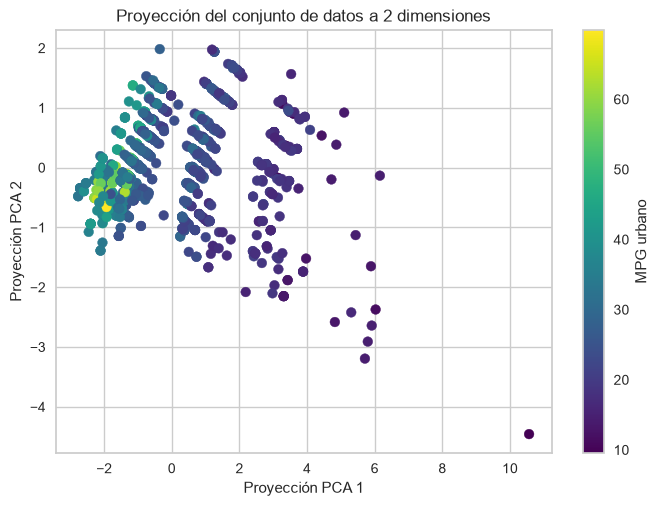

In [474]:

import matplotlib.pyplot as plt
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada:", pca.explained_variance_ratio_.round(3))
print("Acumulada:", pca.explained_variance_ratio_.sum().round(3))
print(pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"]).round(2))

plt.scatter(X_pca[:, 0], X_pca[:, 1],c=df_procesado[mpg], cmap='viridis')
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.colorbar(label="MPG urbano")
plt.show()

Podemos observar como los vehiculos que mas MSG tienen estan concentrados a la izquieda del grafico, y vemos como ese MSG va disminuyendo a medida que nos desplazamos a la derecha de la variable de PCA 1.
Lo hice asi nomas, esto dijo claude:

PC1 (75,9%) es un índice de “tamaño del motor”. Las cuatro variables pesan con el mismo signo: cilindros (0,55), cilindrada (0,54), potencia (0,51) y peso (0,39, algo menos). Un valor alto de PC1 indica un auto con motor grande y potente, y uno bajo, un auto chico. Es el resultado esperado: confirma que peso, potencia, cilindrada y cilindros miden en gran parte lo mismo, y justifica por qué en la regresión sus coeficientes individuales van a ser inestables.

PC2 (16,1%) separa el peso del motor. Casi todo el peso de PC2 viene del peso del vehículo (0,92), con signo contrario al de potencia, cilindrada y cilindros (entre −0,18 y −0,29). Un valor alto de PC2 es un auto pesado para el tamaño de su motor (por ejemplo, un SUV con motor chico), y un valor bajo, un auto liviano con motor grande (típico de un deportivo). Es mi lectura de las cargas; no la verifiqué mirando qué autos caen en cada zona.

El signo de las cargas es arbitrario: el algoritmo podría devolver los componentes con el signo invertido. Lo que importa es cómo se comparan entre sí, y no si son positivas o negativas.

Lo que muestra el gráfico coloreado por MPG
El MPG baja de forma clara de izquierda a derecha. Los puntos amarillos y verdes (MPG de 50 a 80) están en la zona de PC1 bajo (motores chicos), y los violetas (MPG de 10 a 20) en PC1 alto. Es la evidencia visual más fuerte a favor de tu hipótesis: el tamaño del motor, resumido en un solo eje, se asocia con el consumo.
PC2 parece separar menos el color. A igual PC1, el MPG cambia poco entre arriba y abajo, aunque esto es una impresión visual y no una medición.
La caída del MPG no parece lineal. Cambia rápido en los primeros valores de PC1 y se aplana después. Esto respalda el uso de log(mpg) en la regresión.
Los puntos amarillos del extremo izquierdo son muy probablemente los híbridos, que ya vimos que dominan los MPG más altos. Es coherente con incluir la variable hibrido en el modelo.
Hay un punto muy aislado abajo a la derecha (PC1 ≈ 10, PC2 ≈ −4,5), con motor muy grande y liviano para su potencia. Podría ser el motor de 16 cilindros que vimos antes, pero no lo sé. Revisalo antes de decidir si lo dejás.
Dos cosas a tener en cuenta
Colorear por MPG no es circular, porque el MPG no se usó para calcular las componentes. Por eso sí se puede decir que el gráfico muestra una asociación. Pero es una visualización y no un test: la prueba de la hipótesis sigue siendo la regresión con el F global.
Las columnas verticales de puntos (por ejemplo, alrededor de PC1 = 1) vienen de que el peso va en clases de 250 lb y los cilindros toman pocos valores. No es un problema, pero conviene mencionarlo.

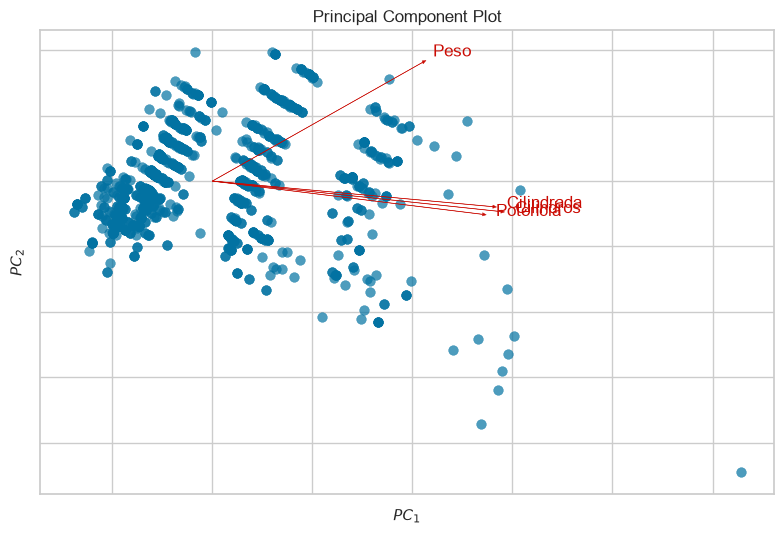

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [475]:
from yellowbrick.features import PCA as PcaViz

# declaramos un objeto de la clase PcaViz:
viz = PcaViz(
      scale=True,          # le vamos a pedir que estandarice
        proj_features=True,  # le pedimos que dibuje las proyecciones de las features originales
        projection=2,        # le pedimos dos proyecciones
        features=["Peso", "Potencia", "Cilindrada", "Cilindros"],  # nombres cortos para las flechas
        colormap="viridis",  # misma escala de color que tu gráfico anterior
        alpha=0.7,      # le pedimos dos proyecciones
)
# lo aplicamos sobre los datos originales
viz.fit_transform(X)
# y pedimos que se grafique
viz.show()

“El biplot muestra que potencia, cilindrada y número de cilindros apuntan en una dirección prácticamente idéntica, lo que indica una correlación muy alta entre ellas y confirma que miden en gran medida el mismo atributo (el tamaño del motor). El peso forma un ángulo mayor con ese grupo, por lo que aporta información en parte independiente, que se refleja en la segunda componente.”

Potencia, cilindrada y cilindros apuntan casi en la misma dirección (hacia la derecha y apenas hacia abajo), tanto que se superponen. Cuando el ángulo entre dos flechas es muy chico, las variables están muy correlacionadas. Esto visualiza la colinealidad que anticipamos para la regresión: miden en gran parte lo mismo.
El peso sale en otra dirección, hacia arriba y a la derecha. Forma un ángulo bastante abierto con las otras tres, así que se asocia con ellas de forma positiva pero menos estrecha. Es la pista visual de que aporta algo de información propia, que es lo que captura PC2.
El largo de las flechas es parecido en las cuatro variables, o sea que todas están bien representadas en estos dos ejes. Es esperable con 92,1% de varianza explicada.

Todo esto coincide con las cargas que obtuviste: PC1 con las cuatro variables positivas y parecidas, y PC2 dominado por el peso (0,92), con signo contrario al de las otras tres.

Lo que muestran los puntos
De izquierda a derecha aumenta el tamaño del motor. El grupo grande a la izquierda son los autos de motor chico, y los puntos que se estiran hacia la derecha son motores más grandes y potentes.
Hay un punto muy aislado abajo a la derecha. Es el mismo valor extremo que vimos en el gráfico anterior, y conviene revisar qué auto es antes de decidir si lo dejás.
Las columnas de puntos se deben a que el peso va en clases de 250 lb y los cilindros toman pocos valores. Además, cada punto es un ensayo y no una configuración, así que varios puntos pueden ser el mismo auto repetido.

### aca iria el analisis de cilindrada y cilindro, pasarlo despues

el punto apartado es el mismo que veniamos viendo y hablando,Un Bugatti Pur Sport: 1.500 hp, 7,993 L de cilindrada, 4.750 lb y 9,5 MPG urbanos, con gasolina de certificación. Es un hiperdeportivo, y el consumo de 9,5 MPG es coherente con ese motor.
Es un hiperdeportivo, no sabia ni que existian

<img src="https://cdn.motor1.com/images/mgl/qnAnv/s1/4x3/2021-bugatti-chiron-pur-sport-front-quarter-action.webp" width="500">

#### correlacion de las variables

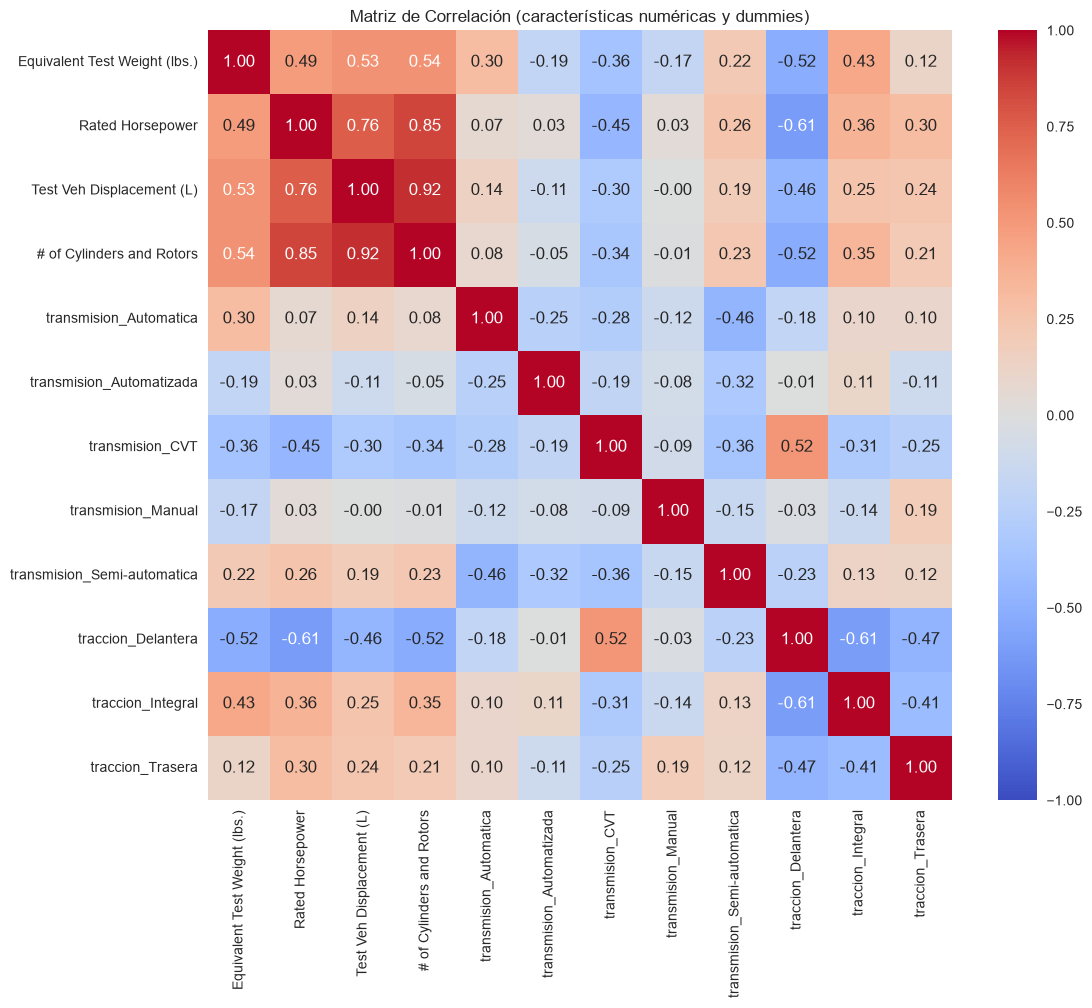

In [476]:
import seaborn as sns
import matplotlib.pyplot as plt

num = ["Equivalent Test Weight (lbs.)",
                  "Rated Horsepower",
                  "Test Veh Displacement (L)",
                  "# of Cylinders and Rotors"]
dums = [c for c in df_procesado.columns if c.startswith(("transmision_", "traccion_"))]

datos = df_procesado[num + dums].astype(float)

# calculamos la matriz de correlación
correlation_matrix = datos.corr()
# la graficamos con un mapa de calor
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de Correlación (características numéricas y dummies)')
plt.show()

Se puede observar como todas las variables tienen una relacion positiva, las que estan mas fuertemente relacionadas, con un coeficiente de 0.92, son las de la cilindrada y el numero de cilindros, que tiene sentido porque tienen nombre parecido qsy.
Luego siguen la potencia con el numero de cilindros (0.84) y por ultimo de los que tienen significancia la cilindrada con la potencia(0.76).
Por lo cual se podrian decir que la potencia, el numero de cilindros y la cilindrada estan relacionados entre si.(eso no seria una hipotesis).

Las de dumies del mismo tipo no se tienen que tener en cueta, ya que no hay un caso de algun vehiculo que tenga por ejemplo traccion delantera exclusivamente y tambien traccion trasera

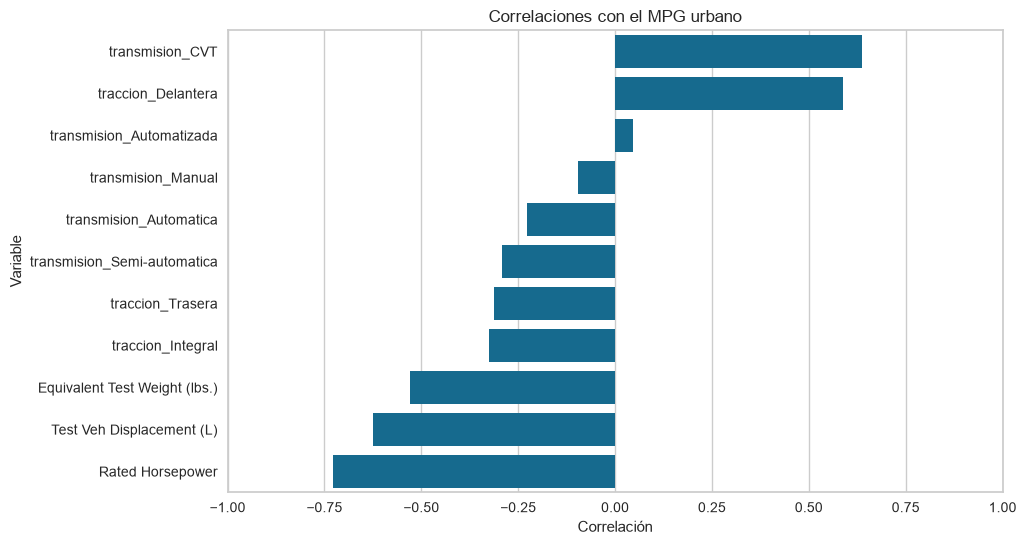

In [477]:
mpg = "RND_ADJ_FE"
num = ["Equivalent Test Weight (lbs.)", "Rated Horsepower", "Test Veh Displacement (L)"]
dums = [c for c in df_procesado.columns if c.startswith(("transmision_", "traccion_"))]

# calculamos la matriz de correlación, ahora incluyendo el MPG
datos = df_procesado[num + dums + [mpg]].astype(float)
correlation_matrix = datos.corr()

# Selecciona solo las correlaciones con el MPG
mpg_correlations = correlation_matrix[mpg].drop(mpg)

# Ordena las correlaciones de mayor a menor
sorted_correlations = mpg_correlations.sort_values(ascending=False)

# Crea un gráfico de barras para visualizar las correlaciones
plt.figure(figsize=(10, 6))
plt.grid(True)
sns.barplot(x=sorted_correlations.values, y=sorted_correlations.index)
plt.title('Correlaciones con el MPG urbano')
plt.xlabel('Correlación')
plt.ylabel('Variable')
plt.xlim([-1, 1])
plt.show()

## T-sne

Before t-SNE: (1082, 4)
After t-SNE: (1082, 2)


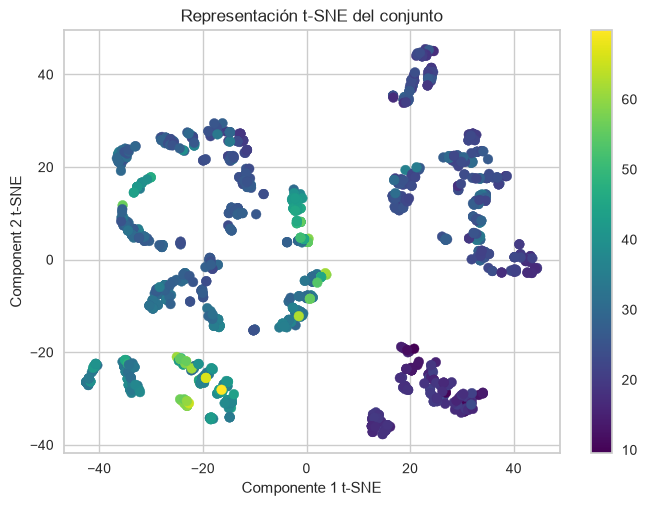

In [478]:
from sklearn.manifold import TSNE

# creamos el objeto, lo fitteamos en nuestros datos y lo aplicamos sobre esos mismos
#X_tsne = TSNE(n_components=2).fit_transform(X_scaled) # sin random state
X_tsne = TSNE(n_components=2, random_state=10).fit_transform(X_scaled)  # con random state
# imprimimos los tamaños antes y después
print('Before t-SNE: {}'.format(X_scaled.shape))
print('After t-SNE: {}'.format(X_tsne.shape))

# graficamos los datos, el color de cada punto representa el valor de la casa
plt.scatter(X_tsne[:,0], X_tsne[:,1], c=df_procesado["RND_ADJ_FE"], cmap='viridis')
plt.grid(True)
plt.xlabel('Componente 1 t-SNE')
plt.ylabel('Component 2 t-SNE')
plt.title('Representación t-SNE del conjunto')
plt.colorbar()
plt.show()

Abajo a la derecha hay un grupo muy oscuro (MPG ~10-15, cerca de (20 a 35, -20 a -35)): probablemente los vehículos más pesados y potentes (V8, pickups o deportivos).
El centro (x entre -5 y 5) tiene puntos verdes/amarillos de alto MPG, posiblemente híbridos, ubicados entre las dos regiones, lo cual tiene sentido porque comparten características con ambos extremos.
Gradiente dentro de las islas: en varias islas el color cambia gradualmente, lo que indica que dentro de un mismo grupo de vehículos el consumo varía con la configuración (transmisión, tracción).

In [479]:
assert len(df_procesado) == X_tsne.shape[0], "X_tsne y df_procesado no coinciden en filas"

for c in ["Drive System Description", "Tested Transmission Type"]:
    print(df_procesado[c].value_counts(dropna=False), "\n")

Drive System Description
Delantera    442
Integral     377
Trasera      263
Name: count, dtype: int64 

Tested Transmission Type
Semi-automatica    402
Automatica         288
CVT                193
Automatizada       157
Manual              42
Name: count, dtype: int64 



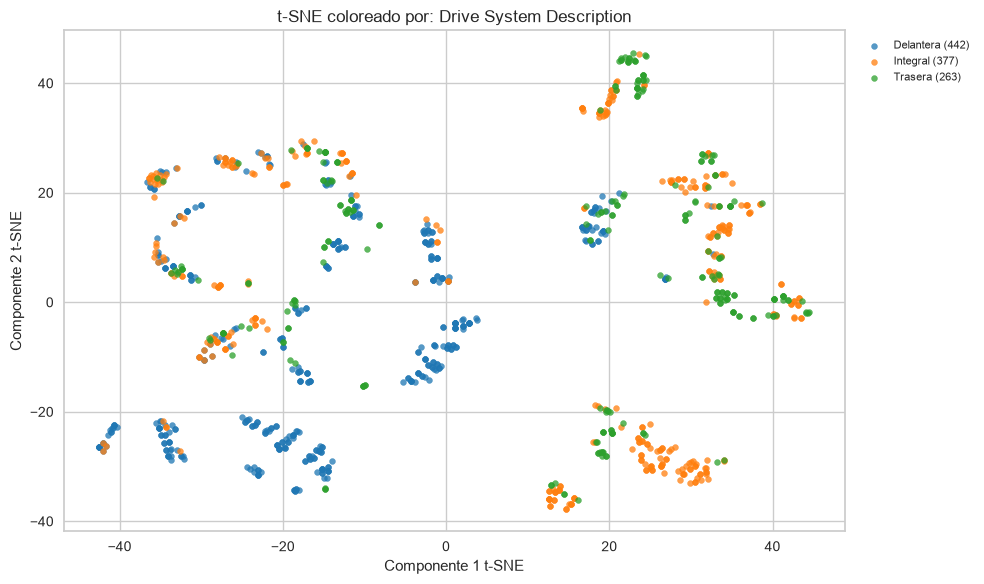

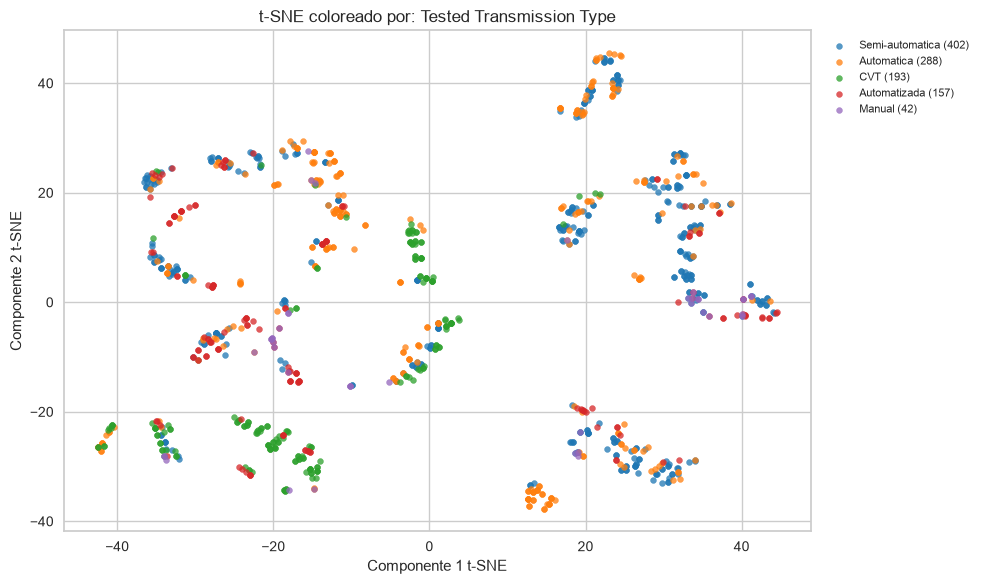

In [480]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

def plot_tsne_cat(col, df=None, max_cats=10, s=18, alpha=0.75, ax=None):
    df = df_procesado if df is None else df
    serie = df[col].reset_index(drop=True).astype(str).str.strip()

    # Agrupar categorías poco frecuentes
    top = serie.value_counts().index[:max_cats]
    serie = serie.where(serie.isin(top), other="Otras")
    categorias = serie.value_counts().index.tolist()

    propia = ax is None
    if propia:
        fig, ax = plt.subplots(figsize=(10, 6))

    cmap = plt.get_cmap("tab10")
    for i, cat in enumerate(categorias):
        m = (serie == cat).values
        ax.scatter(X_tsne[m, 0], X_tsne[m, 1], s=s, alpha=alpha,
                   color=cmap(i % 10), label=f"{cat} ({m.sum()})")

    ax.set_xlabel("Componente 1 t-SNE")
    ax.set_ylabel("Componente 2 t-SNE")
    ax.set_title(f"t-SNE coloreado por: {col}")
    ax.grid(True)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    if propia:
        plt.tight_layout()
        plt.show()

# Un gráfico por variable
plot_tsne_cat("Drive System Description")     # tracción
plot_tsne_cat("Tested Transmission Type")     # transmisión

## Clusters


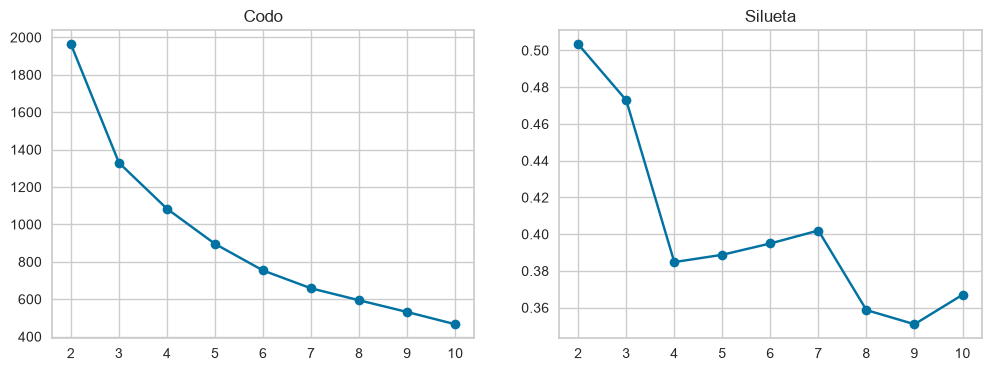

cluster
0    589
1    346
2    147
Name: count, dtype: int64
         Equivalent Test Weight (lbs.)  Rated Horsepower  \
cluster                                                    
0                              4073.85            217.61   
1                              5046.24            375.18   
2                              5364.80            552.57   

         Test Veh Displacement (L)  # of Cylinders and Rotors  RND_ADJ_FE  
cluster                                                                    
0                             2.09                       3.96       34.32  
1                             3.15                       5.83       24.04  
2                             4.94                       8.30       17.50  


In [481]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df_cl = df_procesado.reset_index(drop=True).copy()

# elegir k
ks = range(2, 11)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=10, n_init=10).fit(X_scaled)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X_scaled, km.labels_))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(ks, inercia, marker="o"); axs[0].set_title("Codo")
axs[1].plot(ks, silueta, marker="o"); axs[1].set_title("Silueta")
plt.show()

# modelo final
k = 3  # ajustalo según los gráficos
df_cl["cluster"] = KMeans(n_clusters=k, random_state=10, n_init=10).fit_predict(X_scaled)
print(df_cl["cluster"].value_counts().sort_index())

# perfil de cada cluster en unidades originales (incluye Axle Ratio y mpg para interpretar)
cols = list(X.columns) + [mpg]
print(df_cl.groupby("cluster")[cols].mean().round(2))

me quedo con k=3, es el codo en el enbow plot y es el mejor para maximizar la silueta

In [482]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans

assert len(df_procesado) == X_scaled.shape[0], "X_scaled y df_procesado no coinciden"

k = 3
kmeans = KMeans(n_clusters=k, random_state=10, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

df_cl = df_procesado.reset_index(drop=True).copy()
df_cl["cluster"] = kmeans_labels
print(df_cl["cluster"].value_counts().sort_index())

col_mpg = "RND_ADJ_FE"
num_vars = ["Equivalent Test Weight (lbs.)", "Rated Horsepower",
            "Test Veh Displacement (L)", "# of Cylinders and Rotors"]

dummies = [c for c in df_cl.columns
           if c.startswith(("transmision", "traccion"))
           and df_cl[c].dropna().isin([0, 1]).all()]
print(dummies)

cluster
0    589
1    346
2    147
Name: count, dtype: int64
['transmision_Automatica', 'transmision_Automatizada', 'transmision_CVT', 'transmision_Manual', 'transmision_Semi-automatica', 'traccion_Delantera', 'traccion_Integral', 'traccion_Trasera']


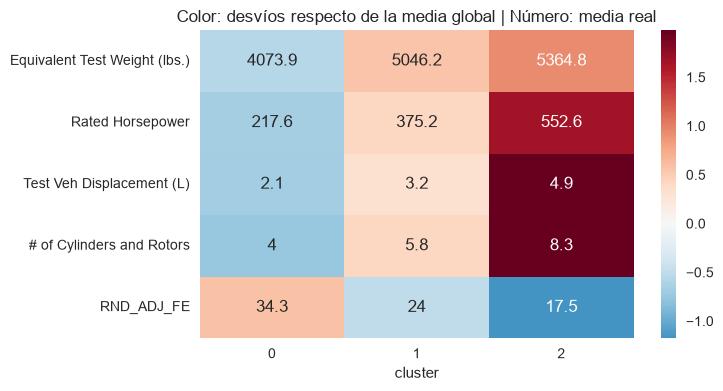

In [483]:
col_mpg = "RND_ADJ_FE"
vars_perfil = num_vars + [col_mpg]

trans_cols = [c for c in dummies if c.startswith("transmision_")]
drive_cols = [c for c in dummies if c.startswith("traccion_")]
df_cl["transmision"] = df_cl[trans_cols].astype(int).idxmax(axis=1).str.replace("transmision_", "")
df_cl["traccion"]    = df_cl[drive_cols].astype(int).idxmax(axis=1).str.replace("traccion_", "")

medias = df_cl.groupby("cluster")[vars_perfil].mean()
z = (medias - df_cl[vars_perfil].mean()) / df_cl[vars_perfil].std()

plt.figure(figsize=(7, 4))
sns.heatmap(z.T, annot=medias.T.round(1), fmt="g", cmap="RdBu_r", center=0)
plt.title("Color: desvíos respecto de la media global | Número: media real")
plt.show()

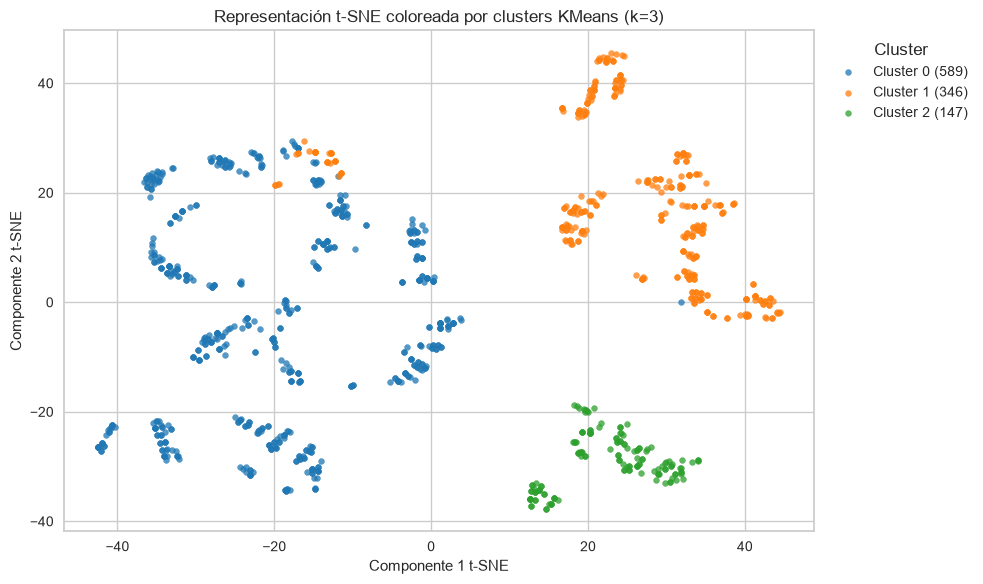

In [484]:
import numpy as np
import matplotlib.pyplot as plt

# Chequeo de alineación: etiquetas, t-SNE y dataframe deben tener las mismas filas
assert len(kmeans_labels) == X_tsne.shape[0] == len(df_cl), \
    "Etiquetas, t-SNE y dataframe no coinciden: recalculá X_scaled, KMeans y t-SNE"

fig, ax = plt.subplots(figsize=(10, 6))
cmap = plt.get_cmap("tab10")

for c in np.unique(kmeans_labels):
    m = kmeans_labels == c
    ax.scatter(X_tsne[m, 0], X_tsne[m, 1], s=18, alpha=0.75,
               color=cmap(c), label=f"Cluster {c} ({m.sum()})")

ax.set_xlabel("Componente 1 t-SNE")
ax.set_ylabel("Componente 2 t-SNE")
ax.set_title(f"Representación t-SNE coloreada por clusters KMeans (k={k})")
ax.grid(True)
ax.legend(title="Cluster", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Regresion lineal

In [485]:
import numpy as np, pandas as pd, statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

num = ["Equivalent Test Weight (lbs.)", "Rated Horsepower",
       "Test Veh Displacement (L)", "# of Cylinders and Rotors"]
ref = ["transmision_Semi-automatica", "traccion_Delantera"]


# solo dummies binarias, sin las referencias
dums = [c for c in df_procesado.columns
        if c.startswith(("transmision_", "traccion_"))
        and c not in ref
        and df_procesado[c].dropna().isin([0, 1]).all()]

cols = num + dums
datos = df_procesado[cols + [mpg, "Test Vehicle ID"]].dropna()   # nulos en cualquier variable

X_reg = datos[cols].copy()
y_reg = datos[mpg].astype(float)

# estandarizar solo numéricas
X_num = pd.DataFrame(StandardScaler().fit_transform(X_reg[num]),
                     columns=num, index=X_reg.index)
X_dum = X_reg[dums].astype(float)
X_scaled_df = sm.add_constant(pd.concat([X_num, X_dum], axis=1))

# ajuste con errores estándar robustos por vehículo
modelo = sm.OLS(y_reg, X_scaled_df).fit(
    cov_type="cluster", cov_kwds={"groups": datos["Test Vehicle ID"]}
)
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:             RND_ADJ_FE   R-squared:                       0.698
Model:                            OLS   Adj. R-squared:                  0.695
Method:                 Least Squares   F-statistic:                     128.5
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          5.64e-153
Time:                        01:30:43   Log-Likelihood:                -3319.3
No. Observations:                1078   AIC:                             6661.
Df Residuals:                    1067   BIC:                             6715.
Df Model:                          10                                         
Covariance Type:              cluster                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

Interpretación:
- El R² indica que el modelo explica aproximadamente el 69,8 % de la variabilidad observada en la eficiencia urbana.
- El R² ajustado es 69,5 %, muy cercano al R². Esto indica que el poder explicativo se mantiene al considerar la cantidad de variables incluidas.
- El p-valor de la prueba global es extremadamente pequeño (menor a 0,05).
Por lo tanto, rechazamos la hipótesis nula de que todos los coeficientes explicativos sean simultáneamente iguales a cero.

Esto proporciona evidencia estadística a favor de tu hipótesis de investigación.

### chequeamos los supuestos

In [486]:
from statsmodels.stats.stattools import (
    durbin_watson,
    jarque_bera,
    omni_normtest
)

residuos = modelo.resid
omnibus, p_omnibus = omni_normtest(residuos)
dw = durbin_watson(residuos)
jb, p_jb, skew, kurtosis = jarque_bera(residuos)
cond = modelo.condition_number

print("Omnibus:", omnibus)
print("Prob(Omnibus):", p_omnibus)
print("Durbin-Watson:", dw)
print("Jarque-Bera:", jb)
print("Prob(JB):", p_jb)
print("Skew:", skew)
print("Kurtosis:", kurtosis)
print("Condition Number:", cond)

Omnibus: 262.51699850921494
Prob(Omnibus): 9.889129653148805e-58
Durbin-Watson: 0.9308147708794507
Jarque-Bera: 754.456736973925
Prob(JB): 1.4852554297976706e-164
Skew: 1.2233859734862949
Kurtosis: 6.287874314837854
Condition Number: 10.423555546057326


##### Normalidad

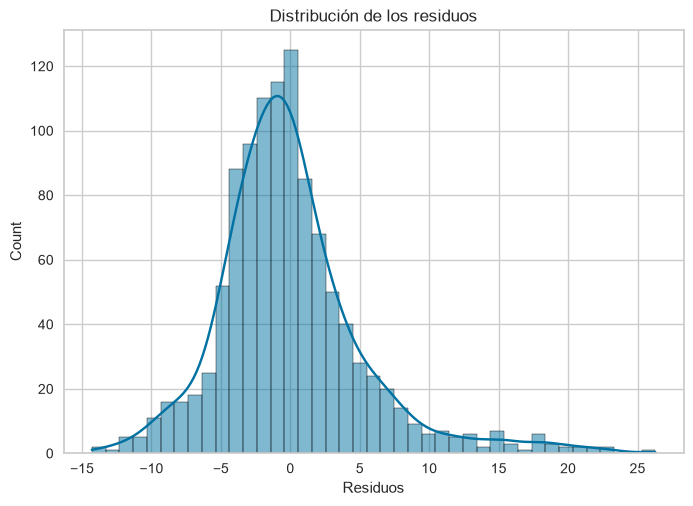

In [487]:
sns.histplot(modelo.resid, kde=True)
plt.title("Distribución de los residuos")
plt.xlabel("Residuos")
plt.show()

Por lo que se muestra en el histograma y los resultados de omnibus y jarque bera se puede ver que **no se cumple el supuesto de normalidad**

##### Homocedasticidad

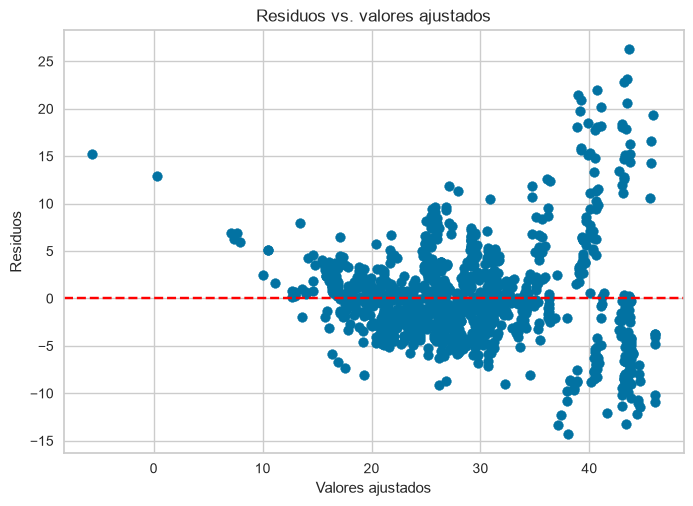

In [488]:
plt.scatter(modelo.fittedvalues, modelo.resid)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Residuos vs. valores ajustados")
plt.show()

Esto sugiere heterocedasticidad, es decir, que la varianza de los errores no es constante.
tambien se da indicios de que no hay linealidad 

##### Independencia

el coeficiente de drubin-watson es muy bajo por lo que se sugiere autocorrelacion positiva 

#### multicolinealidad

In [489]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
v = pd.Series([vif(X_scaled_df.values, i) for i in range(X_scaled_df.shape[1])],
              index=X_scaled_df.columns).drop("const")
print(v.round(1).sort_values(ascending=False))

# of Cylinders and Rotors        10.2
Test Veh Displacement (L)         7.0
Rated Horsepower                  4.4
traccion_Integral                 2.2
Equivalent Test Weight (lbs.)     2.0
traccion_Trasera                  1.9
transmision_CVT                   1.8
transmision_Automatica            1.3
transmision_Automatizada          1.3
transmision_Manual                1.2
dtype: float64


La variable número de cilindros presenta un VIF de 10,2, lo que indica una relación importante con otras variables explicativas.

También encontramos que la cilindrada tiene un VIF de 7,0.

Esto tiene sentido desde el punto de vista técnico: los motores con mayor cilindrada suelen estar relacionados con una mayor cantidad de cilindros y, frecuentemente, con mayor potencia.

Por lo tanto, parte de la información que aporta una variable puede estar contenida en las otras.

Esto puede provocar:
- Coeficientes individuales menos estables.
- Errores estándar más elevados.
- Dificultades para separar el efecto individual de cada característica.
Importante: la multicolinealidad no implica que el modelo completo deje de ser significativo ni que sus predicciones sean necesariamente malas.

#### probamos sin numero de cilindros

In [490]:
import numpy as np, pandas as pd, statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

num = ["Equivalent Test Weight (lbs.)", "Rated Horsepower",
       "Test Veh Displacement (L)"]
ref = ["transmision_Semi-automatica", "traccion_Delantera"]

# chequeo de referencias
for r in ref:
    print(r, "existe" if r in df_procesado.columns else "NO EXISTE")

# solo dummies binarias, sin las referencias
dums = [c for c in df_procesado.columns
        if c.startswith(("transmision_", "traccion_"))
        and c not in ref
        and df_procesado[c].dropna().isin([0, 1]).all()]
print("dummies usadas:", dums)

cols = num + dums
datos = df_procesado[cols + [mpg, "Test Vehicle ID"]].dropna()   # nulos en cualquier variable
print("Observaciones eliminadas:", len(df_procesado) - len(datos))
print("Observaciones restantes:", len(datos))

X_reg = datos[cols].copy()
y_reg = datos[mpg].astype(float)

# estandarizar solo numéricas
X_num = pd.DataFrame(StandardScaler().fit_transform(X_reg[num]),
                     columns=num, index=X_reg.index)
X_dum = X_reg[dums].astype(float)
X_scaled_df = sm.add_constant(pd.concat([X_num, X_dum], axis=1))

# ajuste con errores estándar robustos por vehículo
modelo = sm.OLS(y_reg, X_scaled_df).fit(
    cov_type="cluster", cov_kwds={"groups": datos["Test Vehicle ID"]}
)
print(modelo.summary())

transmision_Semi-automatica existe
traccion_Delantera existe
dummies usadas: ['transmision_Automatica', 'transmision_Automatizada', 'transmision_CVT', 'transmision_Manual', 'traccion_Integral', 'traccion_Trasera']
Observaciones eliminadas: 4
Observaciones restantes: 1078
                            OLS Regression Results                            
Dep. Variable:             RND_ADJ_FE   R-squared:                       0.690
Model:                            OLS   Adj. R-squared:                  0.688
Method:                 Least Squares   F-statistic:                     144.1
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          8.63e-155
Time:                        01:30:43   Log-Likelihood:                -3332.1
No. Observations:                1078   AIC:                             6684.
Df Residuals:                    1068   BIC:                             6734.
Df Model:                           9                                         
Covariance Type: 

COMPARACION
al eliminarla, el modelo reducido pierde capacidad explicativa y empeoran los criterios de información.

Indicador	        Completo	Sin cilindros
Observaciones	    1078	        1078
R²	                0,698	        0,690
R² ajustado	        0,695	        0,688
F-statistic	        128,5	        144,1
AIC	                6661	        6684
BIC	                6715	        6734
Log-Likelihood	    -3319,3	        -3332,1

¿Qué observamos?
- El modelo completo explica un 69,8 % de la variabilidad, frente al 69 % del reducido.
- El R² ajustado también es mayor en el modelo completo.
- El AIC y BIC son menores en el modelo completo, lo que favorece su utilización.
- Ambos modelos tienen la misma cantidad de observaciones, por lo que la comparación es válida en ese aspecto.
El F-statistic del modelo reducido es mayor, pero esto no significa que sea mejor: no conviene comparar directamente los F de modelos con distinta cantidad de predictores.

nos quedamos con el modelo completo

igual vemos si cambio algo en los supuestos

In [491]:
residuos = modelo.resid
omnibus, p_omnibus = omni_normtest(residuos)
dw = durbin_watson(residuos)
jb, p_jb, skew, kurtosis = jarque_bera(residuos)
cond = modelo.condition_number

print("Omnibus:", omnibus)
print("Prob(Omnibus):", p_omnibus)
print("Durbin-Watson:", dw)
print("Jarque-Bera:", jb)
print("Prob(JB):", p_jb)
print("Skew:", skew)
print("Kurtosis:", kurtosis)
print("Condition Number:", cond)

Omnibus: 277.5337323816358
Prob(Omnibus): 5.423950810947655e-61
Durbin-Watson: 0.9206790764318502
Jarque-Bera: 837.0369093135128
Prob(JB): 1.736779034480814e-182
Skew: 1.2747977904912406
Kurtosis: 6.483517252851693
Condition Number: 8.890298924754262


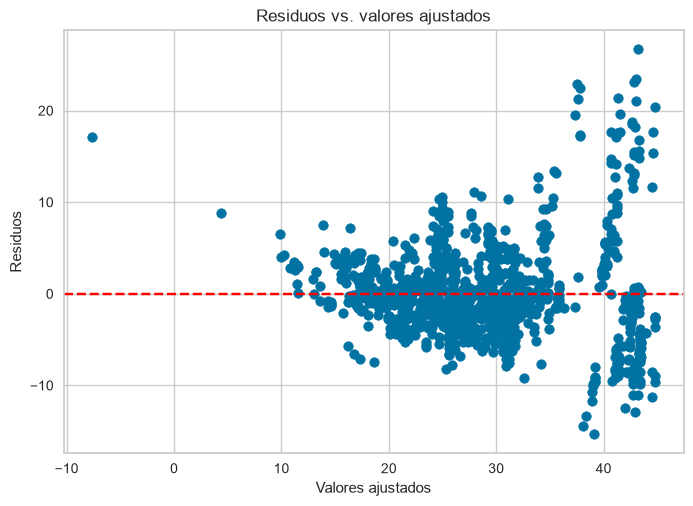

In [492]:
plt.scatter(modelo.fittedvalues, modelo.resid)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Residuos vs. valores ajustados")
plt.show()

NORMALIDAD: no cumple por prob de obnibus y jarque-bera

HOMOCEDASTICIDAD: por el grafico no

LINEALIDAD: por el grafico se ve quen no

INDEPENDENCIA: Durbin-Watson: 0.920, lo que indica autocorrelacion positiva

tampoco cumple ningun supuesto

